# 01 · Data preprocessing

This notebook goes from the raw battery files to clean, model-ready **train / validation / test** tables.


**The key rule:** anything that *learns a number from the data* (a median, a percentile, a mean, a list of categories)
is learned **after** the split and **from the training rows only**. The validation and test rows are only transformed with
those learned numbers. Otherwise information from the test batteries would leak into training.

Sections 3 and 4 only *look* at the data. They don't change it, so it's fine to run them on all rows.

The raw-to-table step itself (HDF5 → one row per reference test) is in `src/features.py`; see the README for the cleaning rules
(match tests by ID, temperature sentinels → missing, capacity measured within one step, SOH at 25 °C only).

In [1]:
from pathlib import Path
import sys, warnings
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import read_info

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 100)
RAW = ROOT / "data" / "raw"
OUT = ROOT / "results" / "preprocessed"; OUT.mkdir(parents=True, exist_ok=True)
SEED = 42

## 1. Data shape

### 1a. Raw data: one HDF5 file per battery cell

Each file holds an `info` table (one line per test: name, start time, schedule) and a `tests/` folder with the raw
time series of each test (voltage, current, temperature, … logged every few seconds).

In [2]:
with h5py.File(RAW / "2_009.h5", "r") as f:
    print("top-level groups:", list(f.keys()))
    print("info table:", f["info"].shape, "rows | columns:", f["info"].dtype.names)
    first = f["tests"][sorted(f["tests"].keys())[0]]
    print("one test contains:", {k: first[k].shape for k in first.keys()})

top-level groups: ['info', 'tests']
info table: (57,) rows | columns: ('idcell', 'idtest', 'idexp', 'expname', 'startdatetime', 'schedulefilename')
one test contains: {'chargecap': (2572,), 'current': (2572,), 'dischargecap': (2572,), 'stepindex': (2572,), 'temperature': (2572,), 'test_time': (2572,), 'voltage': (2572,)}


In [3]:
rows = []
for p in sorted(RAW.glob("*.h5")):
    with h5py.File(p, "r") as f:
        info = read_info(f)
        n_meas = sum(f["tests"][g]["voltage"].shape[0] for g in info.group)
        profile = next((e for e in info.expname if not e.startswith(("RTP", "SetSoC"))), None)
        rows.append(dict(cell_id=p.stem, profile=profile, n_tests=len(info),
                         n_reference_tests=int(info.expname.str.startswith("RTP").sum()),
                         n_RTP25=int((info.expname == "RTP25").sum()), measurement_rows=n_meas))
raw_summary = pd.DataFrame(rows)
display(raw_summary)
print(f"TOTAL: {len(raw_summary)} cells, {raw_summary.profile.nunique()} profiles, "
      f"{raw_summary.n_tests.sum()} tests, {raw_summary.measurement_rows.sum():,} raw measurement rows")

,cell_id,profile,n_tests,n_reference_tests,n_RTP25,measurement_rows
0,2_009,L03,57,31,21,13686306
1,2_010,L03,57,31,21,14090051
2,2_012,L35,59,32,22,21181520
3,2_027,L208,55,31,22,8899176
4,2_030,L210,59,31,22,12165073
5,2_033,L211,56,31,22,8635778
6,2_058,L213,55,30,22,14738026
7,2_067,V212,57,30,22,21273296
8,2_076,L223,23,16,8,13829406
9,2_092,L202,53,30,22,2657030


TOTAL: 15 cells, 14 profiles, 789 tests, 178,641,870 raw measurement rows


### 1b. The feature table

`src/features.py` turns each **reference test** (the periodic health check-up) into one row. Reference tests are run at
5, 15, 25, 35 and 45 °C; SOH is only defined on the 25 °C ones, because capacity changes with test temperature.

In [4]:
df_all = pd.read_csv(ROOT / "results" / "rtp_features.csv", dtype={"cell_id": str})
print("feature table (all reference tests):", df_all.shape)
print("reference tests per test temperature:", df_all.rtp_T_set.value_counts().sort_index().to_dict())

df = df_all[(df_all.rtp_T_set == 25) & df_all.SOH.notna()].reset_index(drop=True)
print("\nlabelled table (25 °C reference tests with SOH):", df.shape)
print(f"{df.cell_id.nunique()} cells | {df.profile.nunique()} profiles")
print("column types:", df.dtypes.astype(str).replace({"str": "text", "object": "text"}).value_counts().to_dict())
df.head()

feature table (all reference tests): (422, 75)
reference tests per test temperature: {5: 18, 15: 33, 25: 306, 35: 35, 45: 30}

labelled table (25 °C reference tests with SOH): (306, 75)
15 cells | 14 profiles
column types: {'float64': 66, 'int64': 5, 'text': 4}


,cell_id,profile,idtest,expname,rtp_T_set,schedule,days_since_start,cum_dis_Ah,cum_chg_Ah,cum_lp_days,cum_lp_Tdays,cum_EFC,cum_lp_T_mean,cap_1C_Ah,cap_1C_spread_Ah,dis1C_energy_Wh,dis1C_meanV,dis1C_dT,dis1C_Tstart,dis1C_IRdrop_ohm,...,prev_lp_chg_Ah,prev_lp_T_mean,prev_lp_T_max,prev_lp_V_mean,prev_lp_V_max,prev_lp_V_min,prev_lp_I_dis_mean,prev_lp_I_chg_mean,prev_lp_I_dis_peak,prev_lp_rest_frac,lp_T_set,lp_CC,lp_ADC,lp_PDC,lp_F,lp_SoC,lp_dSoC,cap_ref_Ah,SOH,rtp_index
0,2_009,L03,3,RTP25,25,RTP_highCurrent,6.05,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,3.153892,0.015331,10.757310,3.419116,14.130642,26.005814,0.050216,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.0,0.2,2.0,3.0,0.2,25.0,2.5,3.153892,100.000000,1
1,2_009,L03,8,RTP25,25,RTP_highCurrent,38.18,283.913227,290.640768,21.268449,945.136654,85.754328,44.438438,3.039816,0.017547,10.338603,3.410906,4.274029,32.090107,0.048997,...,243.658535,44.354520,59.986622,3.537363,4.113259,2.971253,8.963208,0.633708,9.829071,0.028614,40.0,0.2,2.0,3.0,0.2,25.0,2.5,3.153892,96.383034,2
2,2_009,L03,10,RTP25,25,RTP_highCurrent,62.97,557.463613,570.528988,42.526890,1903.760625,168.357105,44.766044,3.020074,0.009092,10.268383,3.405169,4.419529,28.311527,0.051760,...,279.888221,45.093805,59.830425,3.538380,4.113097,2.956660,8.705612,0.606699,9.099365,0.034115,40.0,0.2,2.0,3.0,0.2,25.0,2.5,3.153892,95.757077,3
3,2_009,L03,12,RTP25,25,RTP_highCurrent,90.11,864.110929,884.381804,66.455871,2961.476473,260.969065,44.563053,3.009430,0.012131,10.213527,3.400695,3.965052,28.689898,0.052870,...,313.852816,44.202293,45.234917,3.539713,4.152012,2.980982,8.704023,0.603697,9.410103,0.033289,40.0,0.2,2.0,3.0,0.2,25.0,2.5,3.153892,95.419590,4
4,2_009,L03,14,RTP25,25,RTP_highCurrent,114.93,1144.056672,1169.927607,88.350864,3928.282235,345.370788,44.462296,3.037831,0.087251,10.168394,3.396024,3.906731,28.715073,0.052187,...,285.545803,44.156478,45.243240,3.541439,4.113097,2.982928,8.640849,0.600922,9.012482,0.033953,40.0,0.2,2.0,3.0,0.2,25.0,2.5,3.153892,96.320094,5


## 2. Data dictionary

Every column gets a **role**:

* **id**: identifies the row (never a model input; `cell_id` and `profile` are used to make the splits)
* **target**: what we predict
* **leaky**: is the target or is measured from the same full discharge as the target, so never an input
* **comparison**: measured inside the target test; only used in the leakage comparison, not the main model
* **input**: allowed in the main model

In [5]:
D = {}   # column -> (group, meaning, unit, role)
def add(cols, group, meaning, unit, role):
    for c in cols if isinstance(cols, list) else [cols]:
        D[c] = (group, meaning, unit, role)

add("cell_id", "Identifier", "Battery cell ID (one HDF5 file)", "-", "id")
add("profile", "Identifier", "Ageing profile the cell was cycled under", "-", "id")
add("idtest", "Identifier", "Test number inside the cell's file", "-", "id")
add("expname", "Identifier", "Test name, e.g. RTP25 = reference test at 25 °C", "-", "id")
add("rtp_T_set", "Identifier", "Temperature of the reference test", "°C", "id")
add("schedule", "Test setting", "Check-up procedure: standard (RTP) or high-current (RTP_highCurrent)", "category", "input")
add("SOH", "Target", "State of health = capacity / the cell's first 25 °C capacity", "%", "target")
add(["cap_1C_Ah", "cap_ref_Ah"], "Capacity (leaky)", "Measured capacity / the cell's reference capacity (SOH's numerator / denominator)", "Ah", "leaky")
add("cap_1C_spread_Ah", "Capacity (leaky)", "Difference between the two full discharges in one check-up", "Ah", "leaky")
add("dis1C_energy_Wh", "Capacity (leaky)", "Energy of the full discharge (≈ capacity × voltage)", "Wh", "leaky")
add(["chg_CC_Ah", "chg_CV_Ah", "chg_CC_time_s", "chg_CC_fraction", "dis_C3_CC_Ah"], "Capacity measure",
    "Charge / time of a charge or C/3 discharge step; capacity in disguise", "Ah / s / ratio", "comparison")
add(["chg_CC_V0", "chg_CV_time_s"], "Recharge between the target discharges",
    "Voltage at the start of / time of the recharge right after a full discharge", "V / s", "comparison")
add(["dis1C_meanV", "dis1C_dT", "dis1C_Tstart", "dis1C_IRdrop_ohm", "dis1C_Q_3.8_3.5V", "dis1C_t_to_3.6V_s",
     "relax_dV_after_dis", "rtp_T_mean"], "Inside the target discharge",
    "Shape / temperature / partial window of the full 1C discharge", "V / °C / Ω / Ah / s", "comparison")
add([c for c in df.columns if c.startswith("ica_")], "Inside the target discharge",
    "Incremental-capacity (dQ/dV) peak height / position or area on the 1C discharge", "Ah/V / V / Ah", "comparison")
add([c for c in df.columns if c.startswith("R_") and not c.endswith("_n")], "Pulse resistance",
    "Internal resistance from 10 s current pulses (rises as the cell ages)", "Ω", "input")
add([c for c in df.columns if c.startswith("R_") and c.endswith("_n")], "Pulse resistance",
    "Number of pulses of that size found in the test", "count", "input")
add(["days_since_start", "rtp_index"], "Usage history", "Time since the first test / number of 25 °C check-ups so far", "days / count", "input")
add(["cum_dis_Ah", "cum_chg_Ah", "cum_EFC"], "Usage history", "Total charge moved so far (EFC = equivalent full cycles)", "Ah / cycles", "input")
add(["cum_lp_days", "cum_lp_Tdays", "cum_lp_T_mean"], "Usage history", "Time spent in ageing periods, and their mean temperature", "days / °C", "input")
add([c for c in df.columns if c.startswith("prev_lp_")], "Previous ageing period",
    "Measured conditions of the ageing period just before this check-up (temperature, voltage, current, rest share)", "mixed", "input")
add([c for c in df.columns if c.startswith("lp_")], "Profile design",
    "Designed setting of the profile (T_set, charge/discharge C-rate, frequency, SoC, ΔSoC); from the dataset paper", "mixed", "input")

missing_doc = set(df.columns) - set(D)
assert not missing_doc, f"undocumented columns: {missing_doc}"
dictionary = (pd.DataFrame.from_dict(D, orient="index", columns=["group", "meaning", "unit", "role"])
                .reindex(df.columns).rename_axis("column"))
dictionary["dtype"] = df.dtypes.astype(str).replace({"str": "text", "object": "text"})
dictionary.to_csv(OUT / "data_dictionary.csv")
print(dictionary.role.value_counts().to_string())
dictionary

role
input         43
comparison    22
id             5
leaky          4
target         1


,group,meaning,unit,role,dtype
column,,,,,
cell_id,Identifier,Battery cell ID (one HDF5 file),-,id,text
profile,Identifier,Ageing profile the cell was cycled under,-,id,text
idtest,Identifier,Test number inside the cell's file,-,id,int64
expname,Identifier,"Test name, e.g. RTP25 = reference test at 25 °C",-,id,text
rtp_T_set,Identifier,Temperature of the reference test,°C,id,int64
schedule,Test setting,Check-up procedure: standard (RTP) or high-cur...,category,input,text
days_since_start,Usage history,Time since the first test / number of 25 °C ch...,days / count,input,float64
cum_dis_Ah,Usage history,Total charge moved so far (EFC = equivalent fu...,Ah / cycles,input,float64
cum_chg_Ah,Usage history,Total charge moved so far (EFC = equivalent fu...,Ah / cycles,input,float64


## 3. Missing values

Inspection only; nothing is filled in here. Filling happens in Section 7, **after** the split.

In [6]:
na = df.isna().sum()
miss = (pd.DataFrame({"n_missing": na, "pct": (100 * na / len(df)).round(1),
                      "cells_affected": [df.loc[df[c].isna(), "cell_id"].nunique() for c in df.columns],
                      "role": dictionary.role})
          .query("n_missing > 0").sort_values("n_missing", ascending=False))
print(f"{len(miss)} of {df.shape[1]} columns have missing values; {df.isna().any(axis=1).sum()} of {len(df)} rows have at least one")
miss

32 of 75 columns have missing values; 43 of 306 rows have at least one


,n_missing,pct,cells_affected,role
lp_SoC,21,6.9,1,input
lp_T_set,21,6.9,1,input
lp_ADC,21,6.9,1,input
lp_CC,21,6.9,1,input
lp_dSoC,21,6.9,1,input
lp_F,21,6.9,1,input
lp_PDC,21,6.9,1,input
cum_lp_T_mean,15,4.9,15,input
prev_lp_T_mean,15,4.9,15,input
prev_lp_days,15,4.9,15,input


prev_lp_* missing rows that are the cell's FIRST 25 °C check-up: 15 of 15
lp_* (profile design) missing for profiles: ['V212']
R_0p18C_* missing rows: [['2_067', 3312], ['2_076', 3739], ['2_095', 4757], ['2_095', 4762]]
chg_* missing rows: [['2_108', 5457]]


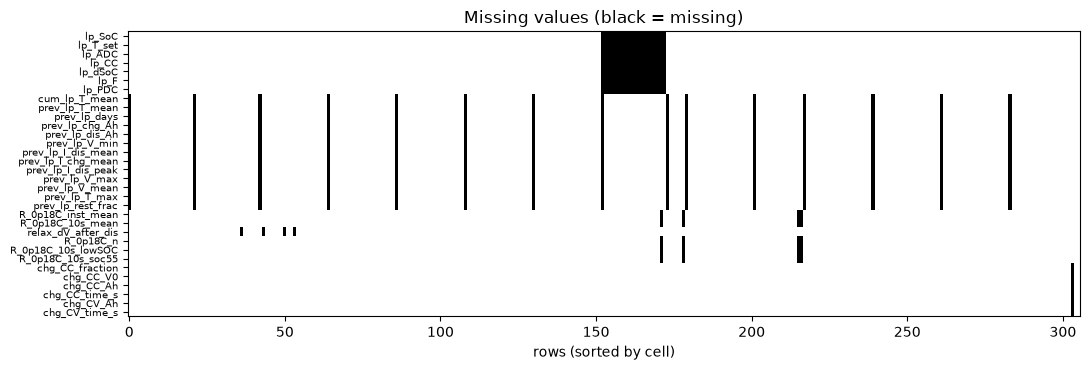

In [7]:
# Where do the gaps come from?
first_rtp = df.groupby("cell_id").rtp_index.transform("min") == df.rtp_index
print("prev_lp_* missing rows that are the cell's FIRST 25 °C check-up:",
      int((df.prev_lp_T_mean.isna() & first_rtp).sum()), "of", int(df.prev_lp_T_mean.isna().sum()))
print("lp_* (profile design) missing for profiles:", df.loc[df.lp_T_set.isna(), "profile"].unique().tolist())
print("R_0p18C_* missing rows:", df.loc[df.R_0p18C_10s_mean.isna(), ["cell_id", "idtest"]].values.tolist())
print("chg_* missing rows:", df.loc[df.chg_CC_Ah.isna(), ["cell_id", "idtest"]].values.tolist())

fig, ax = plt.subplots(figsize=(11, 3.8))
m = df.set_index(["cell_id", "idtest"])[miss.index].isna()
ax.imshow(m.T.values, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(len(miss))); ax.set_yticklabels(miss.index, fontsize=7)
ax.set_xlabel("rows (sorted by cell)"); ax.set_title("Missing values (black = missing)")
plt.tight_layout(); plt.show()

**Reading the result**

| Columns | Why missing | Plan (Section 7) |
|---|---|---|
| `prev_lp_*`, `cum_lp_T_mean` | The first check-up of a cell has no ageing period before it | Median imputation (from training rows) |
| `lp_*` (profile design) | Profile **V212**'s row in the dataset paper is malformed, so its settings were not entered | Median imputation; flagged as a limitation |
| `R_0p18C_*`, `relax_dV_after_dis` | That pulse / rest step was not found in a few tests | Median imputation |
| `chg_*` | One test without the C/2 recharge step | Not used in the main model anyway |

No column is mostly missing, so none is dropped for missingness alone.

## 4. Outliers and physical-range checks

Inspection only. In battery data, an "extreme" value is often **real ageing** (e.g. a cell at 33 % SOH), so the rule here is:
**flag, look, and only remove rows that are physically impossible**. Model-side protection against extreme values
(clipping) is learned in Section 7 from the training rows.

### 4a. Summary statistics

In [8]:
num = df.select_dtypes("number").columns.drop(["idtest", "rtp_T_set"])
desc = df[num].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
q1, q3 = df[num].quantile(0.25), df[num].quantile(0.75)
iqr = q3 - q1
desc["n_IQR_outliers"] = ((df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)).sum()
desc["role"] = dictionary.role
desc.round(4).sort_values("n_IQR_outliers", ascending=False)

,count,mean,std,min,1%,25%,50%,75%,99%,max,n_IQR_outliers,role
lp_CC,285.0,0.0865,0.0914,0.0000,0.0000,0.0500,0.0500,0.0500,0.5000,0.5000,108,input
lp_PDC,285.0,1.6368,0.8884,0.0000,0.0000,1.5000,1.5000,1.5000,3.0000,3.0000,102,input
prev_lp_I_dis_mean,291.0,4.3653,2.0042,0.8901,1.0114,3.6777,4.0662,4.3103,8.8117,8.9978,100,input
prev_lp_I_dis_peak,291.0,4.9037,1.9396,1.6716,2.0979,3.9980,4.3840,4.6391,9.4169,9.8291,97,input
chg_CV_time_s,305.0,8189.3630,1594.6108,5389.9482,5389.9516,8389.9334,8390.0118,9004.8254,10790.0259,10790.0702,94,comparison
prev_lp_rest_frac,291.0,0.1237,0.2233,0.0017,0.0064,0.0111,0.0302,0.0397,0.7627,0.7776,68,input
ica_p2_V,306.0,3.5998,0.0430,3.5100,3.5100,3.5900,3.6100,3.6200,3.7200,3.7200,57,comparison
ica_p3_height,306.0,2.4350,0.8453,0.0048,0.0306,2.3431,2.7387,2.9889,3.3204,3.4085,43,comparison
prev_lp_days,291.0,18.1495,7.9887,0.1653,0.3548,14.9563,21.8665,23.8870,25.9470,25.9595,40,input
dis1C_Q_3.8_3.5V,306.0,0.8080,0.1757,0.0730,0.1439,0.7954,0.8730,0.9032,0.9735,0.9904,39,comparison


The IQR rule (outside 1.5 × the middle 50 %) flags many points, mostly in resistance and usage-history columns. That is
expected: a few cells age much faster than the rest, so their resistance and SOH sit far from the bulk. These are the cells
the project is about, so they must stay.

### 4b. Physical-range checks (would mean a broken measurement)

In [9]:
checks = {
    "SOH outside 20–105 %": ~df.SOH.between(20, 105),
    "capacity outside 0.5–3.6 Ah": ~df.cap_1C_Ah.between(0.5, 3.6),
    "resistance <= 0 or > 1 Ω": (df.filter(regex=r"^R_.*(mean|soc55|lowSOC)$") .le(0) | df.filter(regex=r"^R_.*(mean|soc55|lowSOC)$").gt(1)).any(axis=1),
    "ageing-period voltage outside 2.0–4.3 V": ~df.prev_lp_V_min.between(2.0, 4.3) & df.prev_lp_V_min.notna()
                                               | ~df.prev_lp_V_max.between(2.0, 4.3) & df.prev_lp_V_max.notna(),
    "temperature outside −20–70 °C": ~df.rtp_T_mean.between(-20, 70) | (df.prev_lp_T_max > 70),
    "negative throughput or time": (df[["cum_dis_Ah", "cum_chg_Ah", "days_since_start"]] < 0).any(axis=1),
}
phys = pd.DataFrame({k: [int(v.sum())] for k, v in checks.items()}, index=["rows failing"]).T
phys

,rows failing
SOH outside 20–105 %,0
capacity outside 0.5–3.6 Ah,0
resistance <= 0 or > 1 Ω,0
ageing-period voltage outside 2.0–4.3 V,0
temperature outside −20–70 °C,0
negative throughput or time,0


### 4c. Within-cell checks: SOH jumps and disagreeing discharges

SOH should mostly go **down** over time. A large upward jump, or a big disagreement between the two full discharges inside
one check-up (`cap_1C_spread_Ah`), points to a noisy measurement.

10 rows flagged (SOH jumps up by > 3 points, or the two discharges differ by > 3 %):


,cell_id,profile,idtest,rtp_index,SOH,SOH_change,spread_pct
52,2_012,L35,211,11,77.08,3.61,1.19
62,2_012,L35,234,21,51.51,-8.03,8.18
63,2_012,L35,237,22,56.61,5.11,1.14
120,2_033,L211,1441,13,92.00,-2.41,3.11
128,2_033,L211,1458,21,77.36,7.12,0.33
168,2_067,V212,3304,17,76.35,4.85,0.95
172,2_067,V212,3314,21,55.19,8.19,3.08
214,2_095,L206,4755,14,53.98,-7.00,4.38
215,2_095,L206,4757,15,33.26,-20.71,4.95
216,2_095,L206,4762,16,38.40,5.14,6.46


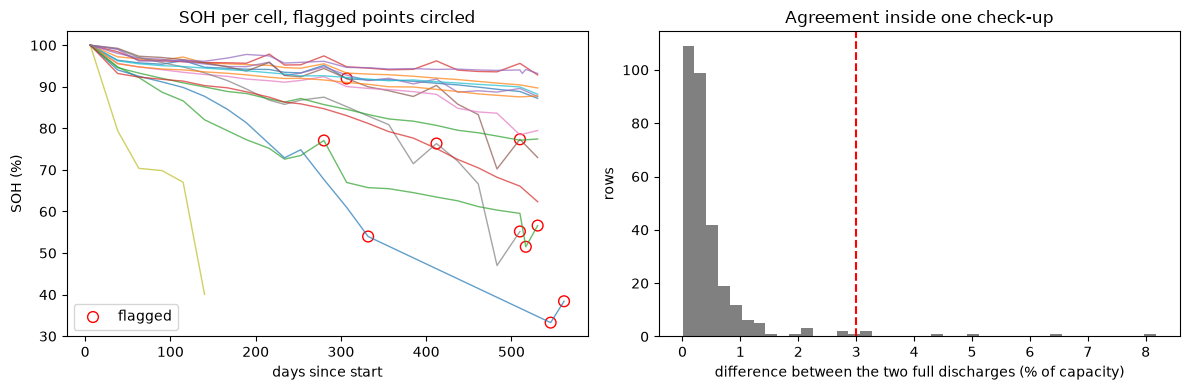

In [10]:
d = df.sort_values(["cell_id", "rtp_index"]).copy()
d["SOH_change"] = d.groupby("cell_id").SOH.diff()
d["spread_pct"] = 100 * d.cap_1C_spread_Ah / d.cap_1C_Ah
flag = d[(d.SOH_change > 3) | (d.spread_pct > 3)]
print(f"{len(flag)} rows flagged (SOH jumps up by > 3 points, or the two discharges differ by > 3 %):")
display(flag[["cell_id", "profile", "idtest", "rtp_index", "SOH", "SOH_change", "spread_pct"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cid, g in d.groupby("cell_id"):
    axes[0].plot(g.days_since_start, g.SOH, lw=1, alpha=0.7)
axes[0].scatter(flag.days_since_start, flag.SOH, s=60, facecolors="none", edgecolors="red", label="flagged")
axes[0].set(xlabel="days since start", ylabel="SOH (%)", title="SOH per cell, flagged points circled"); axes[0].legend()
axes[1].hist(d.spread_pct, bins=40, color="grey"); axes[1].axvline(3, color="red", ls="--")
axes[1].set(xlabel="difference between the two full discharges (% of capacity)", ylabel="rows",
            title="Agreement inside one check-up")
plt.tight_layout(); plt.show()

**Decision:** no row is physically impossible, so **no rows are removed**. The flagged points are small capacity
recoveries after rest periods and a few noisy check-ups. They are real measurements, and the report should mention them
as label noise that no model can predict. Extreme *input* values are handled by clipping in Section 7.

## 5. Target and input columns

This step uses **fixed rules** (the roles from the data dictionary), not values learned from the data, so it is safe to do
before the split.

* **Regression target:** `SOH`
* **Classification target:** `health_class`, made from SOH with project-defined cut-offs: Healthy ≥ 90 %,
  Degraded 80–90 %, EOL-risk < 80 % (80 % is the common automotive end-of-life point)
* **Main inputs:** columns with role *input*: usage history, previous ageing period, profile design, pulse resistance and
  the categorical `schedule`
* **Not inputs:** ids, target, leaky and comparison columns

**Why `cell_id` and `profile` are not one-hot encoded.** They are the labels we hold out. In a leave-cell-out test, the
test cell's ID never appears in training, so its one-hot column would be all zeros: the model learns nothing it can use and
could memorise individual cells instead. The *conditions* of a profile are already given as numbers (`lp_*`, `prev_lp_*`),
and those do carry over to an unseen profile.

In [11]:
TARGET = "SOH"
df["health_class"] = pd.cut(df.SOH, [-np.inf, 80, 90, np.inf], right=False,
                            labels=["EOL-risk (<80)", "Degraded (80-90)", "Healthy (>=90)"])

CAT_FEATURES = ["schedule"]
NUM_FEATURES = [c for c in dictionary.index[dictionary.role == "input"] if c not in CAT_FEATURES]
print(f"{len(NUM_FEATURES)} numeric inputs + {len(CAT_FEATURES)} categorical input")
print("by group:", dictionary.loc[NUM_FEATURES, "group"].value_counts().to_dict())
print("\nhealth classes (all labelled rows):", df.health_class.value_counts().reindex(df.health_class.cat.categories).to_dict())
print("schedule values:", df.schedule.value_counts().to_dict())

42 numeric inputs + 1 categorical input
by group: {'Pulse resistance': 15, 'Previous ageing period': 12, 'Usage history': 8, 'Profile design': 7}

health classes (all labelled rows): {'EOL-risk (<80)': 53, 'Degraded (80-90)': 66, 'Healthy (>=90)': 187}
schedule values: {'RTP': 242, 'RTP_highCurrent': 64}


## 6. Split into train / validation / test

### Why split by cell, not by row
Neighbouring check-ups of the same cell are almost identical. With a random row split, the model sees check-up 7 of a cell
in training and is tested on check-up 8 of the same cell, which is close to copying the answer. So whole **cells** go to
one side only.

### The split
1. **Test:** 3 cells (20 %), held out first and not touched until the final evaluation.
2. **Validation:** 3 of the remaining cells, used to compare models and tune settings.
3. **Train:** the other 9 cells.

This single split is the example used to show the preprocessing. The final model results (notebooks 03–04) repeat the same
preprocessing inside every fold of leave-one-cell-out and leave-one-profile-out cross-validation, so every cell gets a turn
as the test cell. With only 15 cells, one fixed test set of 3 cells would be too small to judge models on its own.

In [12]:
groups = df.cell_id.values
outer = GroupShuffleSplit(n_splits=1, test_size=3, random_state=SEED)
trval_idx, test_idx = next(outer.split(df, groups=groups))
inner = GroupShuffleSplit(n_splits=1, test_size=3, random_state=SEED)
tr_rel, val_rel = next(inner.split(df.iloc[trval_idx], groups=groups[trval_idx]))
train_idx, val_idx = trval_idx[tr_rel], trval_idx[val_rel]

df["split"] = ""
df.loc[train_idx, "split"], df.loc[val_idx, "split"], df.loc[test_idx, "split"] = "train", "validation", "test"
split_tbl = (df.groupby("split")
               .agg(rows=("SOH", "size"), cells=("cell_id", "nunique"), profiles=("profile", "nunique"),
                    SOH_min=("SOH", "min"), SOH_mean=("SOH", "mean"))
               .reindex(["train", "validation", "test"]).round(1))
split_tbl = split_tbl.join(pd.crosstab(df.split, df.health_class))
display(split_tbl)
for s in ["train", "validation", "test"]:
    sub = df[df.split == s]
    print(f"{s:10s} cells: {sorted(sub.cell_id.unique())}  profiles: {sorted(sub.profile.unique())}")

# no cell may appear in two parts
sets = {s: set(df.loc[df.split == s, "cell_id"]) for s in ["train", "validation", "test"]}
assert not (sets["train"] & sets["validation"]) and not (sets["train"] & sets["test"]) and not (sets["validation"] & sets["test"])
print("\nOK: no cell appears in more than one part")

,rows,cells,profiles,SOH_min,SOH_mean,EOL-risk (<80),Degraded (80-90),Healthy (>=90)
split,,,,,,,,
train,176,9,9,33.3,86.9,40,32,104
validation,65,3,3,62.4,87.4,13,21,31
test,65,3,3,87.2,92.5,0,13,52


train      cells: ['2_012', '2_027', '2_030', '2_033', '2_058', '2_067', '2_076', '2_095', '2_108']  profiles: ['L206', 'L207', 'L208', 'L210', 'L211', 'L213', 'L223', 'L35', 'V212']
validation cells: ['2_010', '2_101', '2_104']  profiles: ['L03', 'L214', 'L216']
test       cells: ['2_009', '2_092', '2_098']  profiles: ['L03', 'L202', 'L209']

OK: no cell appears in more than one part


In [13]:
# For comparison: what a random ROW split would have done
rng = np.random.default_rng(SEED)
rand_test = rng.random(len(df)) < 0.2
shared = set(df.cell_id[rand_test]) & set(df.cell_id[~rand_test])
print(f"random 80/20 row split: {len(shared)} of 15 cells have rows in BOTH train and test -> optimistic results")

random 80/20 row split: 15 of 15 cells have rows in BOTH train and test -> optimistic results


**Things to keep in mind about this split**
* Some profiles have only one cell, so a held-out cell usually also means a held-out profile.
* The EOL-risk class comes from only 8 cells, so a 3-cell validation or test set may contain few or none of them.
  That's another reason the final results use cross-validation over all cells.

## 7. Preprocessing: fitted on the training rows only

Each step is a scikit-learn transformer. `fit` learns its numbers from **train**; `transform` applies them to train,
validation and test.

| Step | Columns | Learns from train | Why |
|---|---|---|---|
| 1. Drop unusable columns | numeric | which columns are entirely missing or constant in train | A column with no information in train can't be learned from |
| 2. Clip outliers | numeric | 1st and 99th percentile of each column | Stops one extreme value from dominating linear models and SVR; values are capped, not removed |
| 3. Impute missing values | numeric | median of each column | Models can't take blanks; the median isn't pulled by outliers |
| 4. Scale | numeric | mean and standard deviation | Puts resistances (≈0.05 Ω) and throughput (≈1000 Ah) on the same scale for Ridge / SVR |
| 5. Impute missing values | categorical | most frequent value | (no gaps today, but safe) |
| 6. One-hot encode | categorical | list of categories | Turns `schedule` into 0/1 columns; a category never seen in train becomes all zeros |

Tree models (random forest, gradient boosting) don't need step 4, but it doesn't hurt them.

In [14]:
class DropUnusable(BaseEstimator, TransformerMixin):
    # Drop columns that are all-missing or constant in the TRAINING rows.
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.keep_ = [c for c in X.columns if X[c].notna().any() and X[c].nunique(dropna=True) > 1]
        self.dropped_ = [c for c in X.columns if c not in self.keep_]
        return self
    def transform(self, X):
        return pd.DataFrame(X)[self.keep_]
    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.keep_, dtype=object)

class PercentileClipper(BaseEstimator, TransformerMixin):
    # Cap each column at percentiles learned from the TRAINING rows (missing values are left missing).
    def __init__(self, lower=1, upper=99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.low_ = X.quantile(self.lower / 100)
        self.high_ = X.quantile(self.upper / 100)
        return self
    def transform(self, X):
        return pd.DataFrame(X).clip(self.low_, self.high_, axis=1)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.low_.index, dtype=object)

numeric_pipe = Pipeline([
    ("drop_unusable", DropUnusable()),
    ("clip", PercentileClipper(1, 99)),
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([("num", numeric_pipe, NUM_FEATURES),
                                ("cat", categorical_pipe, CAT_FEATURES)],
                               verbose_feature_names_out=False).set_output(transform="pandas")

X = df[NUM_FEATURES + CAT_FEATURES]
y = df[TARGET].values
X_train, X_val, X_test = X.iloc[train_idx], X.iloc[val_idx], X.iloc[test_idx]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

preprocess.fit(X_train)                       # <- the ONLY fit: training rows
Xp_train = preprocess.transform(X_train)
Xp_val = preprocess.transform(X_val)
Xp_test = preprocess.transform(X_test)
print("before:", X_train.shape, X_val.shape, X_test.shape)
print("after: ", Xp_train.shape, Xp_val.shape, Xp_test.shape)

before: (176, 43) (65, 43) (65, 43)
after:  (176, 44) (65, 44) (65, 44)


### 7a. What each step learned from the training rows

In [15]:
num = preprocess.named_transformers_["num"]
drop, clip, imp, sc = (num.named_steps[k] for k in ["drop_unusable", "clip", "impute", "scale"])
print("1. dropped (all-missing or constant in train):", drop.dropped_ or "none")

learned = pd.DataFrame({"clip_low (p1)": clip.low_, "clip_high (p99)": clip.high_,
                        "impute_median": imp.statistics_, "scale_mean": sc.mean_, "scale_std": sc.scale_},
                       index=drop.keep_)
learned["missing_in_train"] = X_train[drop.keep_].isna().sum()
display(learned.round(4))

ohe = preprocess.named_transformers_["cat"].named_steps["onehot"]
print("6. one-hot categories learned:", dict(zip(CAT_FEATURES, [list(c) for c in ohe.categories_])))

1. dropped (all-missing or constant in train): none


,clip_low (p1),clip_high (p99),impute_median,scale_mean,scale_std,missing_in_train
days_since_start,6.0400,534.5700,252.8600,264.6576,160.6395,0
cum_dis_Ah,0.0000,3981.5387,761.5626,948.9612,866.0336,0
cum_chg_Ah,0.0000,4271.8004,811.3440,986.0428,922.5419,0
cum_lp_days,0.0000,421.3349,192.8283,196.7283,139.8387,0
cum_lp_Tdays,0.0000,17918.9651,936.8945,3222.6434,4443.7659,0
cum_EFC,0.0000,1231.8417,232.7335,288.8066,266.8959,0
cum_lp_T_mean,1.4467,47.6600,21.1819,19.0520,16.7016,9
R_1p35C_10s_mean,0.0579,0.1162,0.0675,0.0718,0.0142,0
R_1p35C_inst_mean,0.0449,0.0796,0.0530,0.0555,0.0079,0
R_1p35C_n,6.0000,7.0000,7.0000,6.9432,0.2315,0


6. one-hot categories learned: {'schedule': ['RTP', 'RTP_highCurrent']}


In [16]:
# How much did clipping change? (counted on the raw values, per part)
def n_clipped(Xpart):
    v = Xpart[drop.keep_]
    return int(((v < clip.low_) | (v > clip.high_)).sum().sum())
print({name: n_clipped(part) for name, part in [("train", X_train), ("validation", X_val), ("test", X_test)]},
      "values capped")

# One-hot result
print("\none-hot columns:", [c for c in Xp_train.columns if c.startswith("schedule")])
display(pd.concat([X_train.schedule.rename("schedule (raw)"),
                   Xp_train.filter(like="schedule_")], axis=1).drop_duplicates())

{'train': 104, 'validation': 127, 'test': 237} values capped

one-hot columns: ['schedule_RTP', 'schedule_RTP_highCurrent']


,schedule (raw),schedule_RTP,schedule_RTP_highCurrent
42,RTP_highCurrent,0.0,1.0
64,RTP,1.0,0.0


**Note on clipping.** Far more values are capped in validation and test than in train. That isn't an error: the held-out
cells come from profiles whose conditions (temperature, current, ageing speed) partly lie **outside** the training range,
and clipping pulls them back to the edge of what the model has seen. This makes linear models and SVR safer on extreme
inputs, but it also means the model can't extrapolate beyond the training range. Keep this in mind for the
interpolation vs extrapolation analysis, and check on the validation cells whether clipping helps or hurts
(set `PercentileClipper(0, 100)` to switch it off).

### 7b. Why fitting on train only matters: a small demonstration

If the imputer and scaler were fitted on **all** rows, the medians and means would partly come from the validation and
test cells. The table below compares the two. The differences are large (temperature-related columns move by more than
60 %), because the held-out cells were aged under different conditions from the training cells. Fitting on all rows would
quietly tell the model what the "unseen" conditions look like, which is exactly the leak we are trying to avoid.

In [17]:
leaky_scaler = Pipeline([("drop", DropUnusable()), ("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
leaky_scaler.fit(X[NUM_FEATURES])                         # WRONG: includes validation + test cells
k = leaky_scaler.named_steps["drop"].keep_
cmp = pd.DataFrame({"mean (train only)": pd.Series(sc.mean_, drop.keep_),
                    "mean (all rows: leaky)": pd.Series(leaky_scaler.named_steps["scale"].mean_, k)}).dropna()
cmp["rel_diff_%"] = 100 * (cmp.iloc[:, 1] - cmp.iloc[:, 0]).abs() / cmp.iloc[:, 0].abs().replace(0, np.nan)
cmp.sort_values("rel_diff_%", ascending=False).head(8).round(3)

,mean (train only),mean (all rows: leaky),rel_diff_%
cum_lp_Tdays,3222.643,5405.475,67.734
lp_T_set,18.523,30.458,64.433
cum_lp_T_mean,19.052,31.159,63.547
prev_lp_T_mean,18.934,30.965,63.539
prev_lp_T_max,24.476,35.040,43.161
prev_lp_rest_frac,0.092,0.119,28.866
lp_F,0.135,0.155,14.669
lp_dSoC,29.730,25.768,13.327


## 8. Final checks and saved outputs

In [18]:
for name, part in [("train", Xp_train), ("validation", Xp_val), ("test", Xp_test)]:
    assert part.isna().sum().sum() == 0, f"{name} still has missing values"
    assert list(part.columns) == list(Xp_train.columns)
print("OK: no missing values left, and all three parts have the same", Xp_train.shape[1], "columns")
stds = Xp_train[drop.keep_].std(ddof=0)
print("train columns after scaling: largest |mean| =", round(float(Xp_train[drop.keep_].mean().abs().max()), 6),
      "| median std =", round(float(stds.median()), 3))
print("columns that became constant after clipping (std 0, carry no information):", stds[stds < 1e-9].index.tolist() or "none")
print("validation / test are NOT exactly mean 0 / std 1 (as expected, they were only transformed):",
      round(float(Xp_val[drop.keep_].mean().abs().mean()), 3), "/", round(float(Xp_test[drop.keep_].mean().abs().mean()), 3))

OK: no missing values left, and all three parts have the same 44 columns
train columns after scaling: largest |mean| = 0.0 | median std = 1.0
columns that became constant after clipping (std 0, carry no information): ['R_1p13C_n', 'R_0p18C_n']
validation / test are NOT exactly mean 0 / std 1 (as expected, they were only transformed): 0.397 / 0.492


In [19]:
keep_ids = ["cell_id", "profile", "idtest", "rtp_index"]
for name, idx, Xp in [("train", train_idx, Xp_train), ("validation", val_idx, Xp_val), ("test", test_idx, Xp_test)]:
    out = pd.concat([df.iloc[idx][keep_ids].reset_index(drop=True), Xp.reset_index(drop=True),
                     df.iloc[idx][["SOH", "health_class"]].reset_index(drop=True)], axis=1)
    out.to_csv(OUT / f"{name}.csv", index=False)
df[keep_ids + ["split"]].to_csv(OUT / "split_assignment.csv", index=False)
learned.to_csv(OUT / "fitted_preprocessing_parameters.csv")
pd.Series(NUM_FEATURES + CAT_FEATURES, name="feature").to_csv(OUT / "main_feature_list.csv", index=False)
print("saved to", OUT.relative_to(ROOT), ":", sorted(p.name for p in OUT.iterdir()))

saved to results/preprocessed : ['data_dictionary.csv', 'fitted_preprocessing_parameters.csv', 'main_feature_list.csv', 'split_assignment.csv', 'test.csv', 'train.csv', 'validation.csv']


## Summary

* **Raw data:** 15 cells / 14 profiles, turned by `src/features.py` into 422 reference-test rows, of which **306** are
  25 °C check-ups with an SOH label.
* **Columns:** 75, each documented with a role (`data_dictionary.csv`). The main model uses the *input* columns only;
  capacity and same-discharge measurements are excluded to avoid target leakage.
* **Missing values:** explained by the data (first check-up has no previous ageing period, V212 has no design
  settings, a few missing pulse steps), filled with **training medians**.
* **Outliers:** no physically impossible values, so no rows are removed. A few noisy check-ups are flagged as label
  noise; extreme inputs are capped at the **training** 1st / 99th percentiles.
* **Encoding:** `schedule` is one-hot encoded. `cell_id` / `profile` are not encoded: they define the splits, and an
  unseen cell or profile would have no matching column.
* **Split:** by cell into train (9) / validation (3) / test (3); no cell appears in two parts. Every preprocessing step is
  fitted on train only. The final evaluation repeats this inside leave-cell-out and leave-profile-out cross-validation.